<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Treasury Fiscal Data](https://github.com/Query-farm/vgi-treasury)

Query federal debt, operating cash, deposits, withdrawals and public debt transactions, and discover Fiscal Data endpoint fields.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-treasury/blob/main/notebooks/03_one_report_date_many_measurements.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-treasury/blob/main/notebooks/README.md)


## 03 · One report date can contain many periods and measurement types

A Monthly Treasury Statement report includes prior-year monthly rows, current-year
monthly rows, headers and year-to-date totals. A rate table with the same report date
contains security-specific percentages and aggregate rates. What must SQL select
before either table becomes a meaningful comparison?

We label raw fields, reconcile generic JSON with the typed monthly table, use its
parent hierarchy to select current-fiscal-year months, and inspect interest rates
separately. **No conversion from these rates to interest expense is attempted.**
Both original public responses cover January and February 2024 and are bundled with
[recorded provenance](fixtures/discovery-provenance.json); no synthetic values or
live account operations are involved.

### Select the report, not an implied single observation

`REPORT_DATE = "2024-01-31"` becomes **2024-02-29** in the experiment. This chooses one
record-date population from each fixed capture. The represented fiscal months must
be resolved from hierarchy and row codes, not inferred from record_date alone.
Metadata labels were captured in November 2026; they are not claimed to be a historical
snapshot of labels available when these reports were first published.

In [1]:
REPORT_DATE = "2024-01-31"  # Experiment: "2024-02-29".

### Run this notebook

Read the saved results on GitHub or choose **Open in Colab** and Run All. Setup installs
the shared base tools, preserving compatible preloaded data/plotting libraries.
Initial packages, verified companions, VGI and the released worker need internet.
The default analysis then uses recorded public Treasury rows over loopback HTTP;
it does not generate synthetic replacement values or contact the official API.

uv supplies the worker's separate Python 3.13+ environment. A fresh preloaded Python
3.12 notebook-only run verifies the common setup path; actual hosted Colab has not
been tested. No source checkout, worker build or real credential is required.

In [2]:
import importlib.metadata as packages

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.30":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.30"
from vgi_notebooks import check_runtime

check_runtime()
if packages.version("vgi-example-notebooks") != "0.3.30":
    raise RuntimeError("Install shared tools v0.3.30, then restart and run all.")

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from vgi_notebooks.bootstrap import prepare
from vgi_notebooks.presentation import finish, prose, theme
from vgi_notebooks.session import connect

prepare("treasury")
%matplotlib inline
theme()
session = connect(globals())
connection = session.connection
Path("artifacts").mkdir(exist_ok=True)

from multi_recorded_api import RecordedFiscalSource

source = RecordedFiscalSource()
SOURCE_STAMP = source.manifest["captures"][0]["captured_at_utc"][:10]
PROVENANCE = f"US Treasury Fiscal Data · recorded public rows · captured {SOURCE_STAMP} · released v0.1.0"

if REPORT_DATE not in {"2024-01-31", "2024-02-29"}:
    raise ValueError("REPORT_DATE must be 2024-01-31 or 2024-02-29")
months = rates = coverage = checks = pd.DataFrame()

### Read the measurement contract before comparing values

The clean release ATTACH uses no credentials, and the shared session begins with an
empty temporary secret store. `fields` retrieves labels/types from one source row's
metadata; here those descriptors come from the recorded response. `records` preserves
JSON strings, while `monthly_statement` provides typed decimals. We materialize each
separately, then compare their results locally. Fields described as CURRENCY do not
by themselves establish a conversion to a website's display scale.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'treasury' (TYPE vgi,
 LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-treasury@v0.1.0 vgi-treasury-worker');

,Success


In [5]:
%%sql
CREATE TABLE field_info AS SELECT * FROM treasury.main.fields('v1/accounting/mts/mts_table_1');
CREATE TABLE raw_monthly AS SELECT * FROM treasury.main.records('v1/accounting/mts/mts_table_1',
 start_date := '{{ REPORT_DATE }}',end_date := '{{ REPORT_DATE }}',page_size := 10,max_rows := 0);
CREATE TABLE monthly AS SELECT * FROM treasury.main.monthly_statement(
 start_date := '{{ REPORT_DATE }}',end_date := '{{ REPORT_DATE }}',page_size := 10,max_rows := 0);
CREATE TABLE interest AS SELECT * FROM treasury.main.average_interest_rates(
 start_date := '{{ REPORT_DATE }}',end_date := '{{ REPORT_DATE }}',page_size := 10,max_rows := 0);
SELECT field_name,label,source_type,source_format FROM field_info
WHERE field_name LIKE '%amt' ORDER BY field_name;
SELECT data_type_cd,record_type_cd,count(*) AS rows,
 count(current_month_gross_rcpt_amt) AS rows_with_receipts
FROM monthly GROUP BY data_type_cd,record_type_cd ORDER BY data_type_cd,record_type_cd;


,data_type_cd,record_type_cd,rows,rows_with_receipts
0,D,MTH,16,16
1,S,SL,2,0
2,T,SL,2,2


In [6]:
%%sql
SELECT f.field_name,f.label,f.source_type,f.source_format,
 r.record_json::JSON->>f.field_name AS original_value_text
FROM field_info f CROSS JOIN raw_monthly r
WHERE r.record_json::JSON->>'src_line_nbr'='2' AND f.field_name LIKE '%amt'
ORDER BY f.field_name;

,field_name,label,source_type,source_format,original_value_text
0,current_month_dfct_sur_amt,Current Month Deficit Surplus Amount,CURRENCY,$10.20,87874164113.17
1,current_month_gross_outly_amt,Current Month Gross Outlay Amount,CURRENCY,$10.20,406374243972.26
2,current_month_gross_rcpt_amt,Current Month Gross Receipts Amount,CURRENCY,$10.20,318500079859.09


### Follow parent IDs to avoid duplicate months and totals

The same report can contain two rows called January, one for each fiscal year.
Join each detail row to its parent header and select the header matching the report's
fiscal year. Keep `data_type_cd='D'` and `record_type_cd='MTH'` for individual months;
retain `T` totals separately as independent checks. Summing headers, prior-year rows
and totals together would misstate the population.

Amounts remain exact **API currency units**. Charts divide by 10⁹ only for display;
the worker does not infer that Treasury's website uses the same scale. A positive
`current_month_dfct_sur_amt` here equals outlays minus receipts; negative is surplus.

In [7]:
%%sql
CREATE TABLE labelled_monthly AS
SELECT child.*,parent.classification_desc AS fiscal_year_label
FROM monthly child LEFT JOIN monthly parent
 ON child.record_date=parent.record_date AND child.parent_id=parent.classification_id;
CREATE TABLE fiscal_months AS SELECT * FROM labelled_monthly
WHERE fiscal_year_label='FY ' || record_fiscal_year
 AND data_type_cd='D' AND record_type_cd='MTH';
CREATE TABLE fiscal_total AS SELECT * FROM labelled_monthly
WHERE fiscal_year_label='FY ' || record_fiscal_year AND data_type_cd='T';
SELECT fiscal_year_label,classification_desc,current_month_gross_rcpt_amt::VARCHAR AS receipts_api_units,
 current_month_gross_outly_amt::VARCHAR AS outlays_api_units,current_month_dfct_sur_amt::VARCHAR AS deficit_api_units
FROM fiscal_months ORDER BY src_line_nbr;
SELECT fiscal_year_label,classification_desc,current_month_dfct_sur_amt::VARCHAR AS ytd_deficit_api_units
FROM fiscal_total;

,fiscal_year_label,classification_desc,ytd_deficit_api_units
0,FY 2024,Year-to-Date,531860024312.08


In [8]:
%%sql months <<
SELECT classification_desc,src_line_nbr,current_month_gross_rcpt_amt/1e9 AS receipts_billions,
 current_month_gross_outly_amt/1e9 AS outlays_billions,current_month_dfct_sur_amt/1e9 AS deficit_billions
FROM fiscal_months ORDER BY src_line_nbr;

In [9]:
report_population = connection.execute("SELECT count(*) FROM monthly").fetchone()[0]
ytd = connection.execute("SELECT current_month_dfct_sur_amt::VARCHAR FROM fiscal_total").fetchone()[0]
prose(
    f"The **{REPORT_DATE}** report contains **{report_population} rows** but only **{len(months)} "
    f"current-fiscal-year monthly details**. Their deficit/surplus amounts sum to the separately "
    f"reported YTD value, **{ytd} API currency units**. Headers stay missing rather than zero. "
    "The record date identifies this report's population; it does not turn all of its rows into January "
    "or February observations."
)

The **2024-01-31** report contains **20 rows** but only **4 current-fiscal-year monthly details**. Their deficit/surplus amounts sum to the separately reported YTD value, **531860024312.08 API currency units**. Headers stay missing rather than zero. The record date identifies this report's population; it does not turn all of its rows into January or February observations.

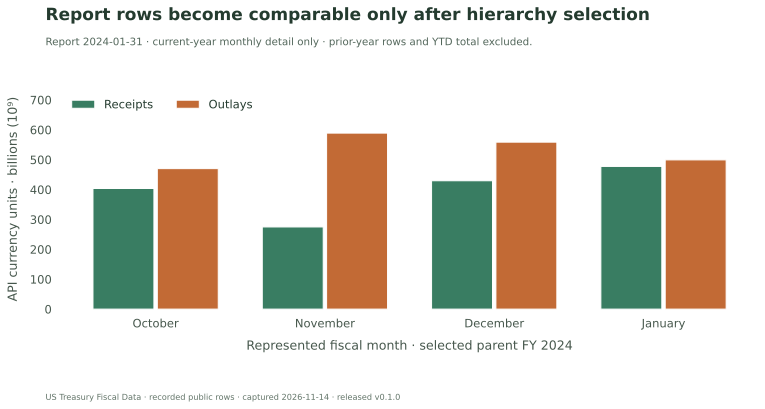

In [10]:
x = np.arange(len(months))
fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(x - 0.19, months.receipts_billions, 0.36, label="Receipts", color="#397D62")
ax.bar(x + 0.19, months.outlays_billions, 0.36, label="Outlays", color="#C26A35")
ax.set_xticks(x, months.classification_desc)
ax.set_ylabel("API currency units · billions (10⁹)")
ax.set_xlabel("Represented fiscal month · selected parent FY 2024")
ax.legend(loc="upper left", ncol=2)
ax.set_ylim(0, float(max(months.receipts_billions.max(), months.outlays_billions.max())) * 1.25)
finish(
    fig,
    "Report rows become comparable only after hierarchy selection",
    f"Report {REPORT_DATE} · current-year monthly detail only · prior-year rows and YTD total excluded.",
    PROVENANCE,
    name=f"monthly-hierarchy-{REPORT_DATE}",
)

### Read rates as percentages, not expenses or arithmetic averages

The interest table reports average rates on outstanding securities, including
aggregate rows. Select the six **Marketable** component rows and retain “Total
Marketable” separately. A simple unweighted mean of component percentages gives each
security class equal weight; the published aggregate need not equal it. This API
response supplies no matching principal weights, duration exposures or expense
period that would support calculating interest dollars or pricing a new security.

In [11]:
%%sql
CREATE TABLE marketable_rates AS SELECT *,
 CASE security_desc WHEN 'Treasury Inflation-Protected Securities (TIPS)' THEN 'TIPS'
 WHEN 'Treasury Floating Rate Notes (FRN)' THEN 'Floating-rate notes'
 WHEN 'Treasury Bills' THEN 'Bills' WHEN 'Treasury Notes' THEN 'Notes'
 WHEN 'Treasury Bonds' THEN 'Bonds' ELSE security_desc END AS short_label
FROM interest WHERE security_type_desc='Marketable' AND security_desc<>'Total Marketable';
CREATE TABLE rate_summary AS
SELECT (SELECT avg_interest_rate_amt FROM interest WHERE security_desc='Total Marketable') AS published_pct,
 avg(avg_interest_rate_amt) AS unweighted_pct,count(*) AS components FROM marketable_rates;
SELECT security_desc,avg_interest_rate_amt::VARCHAR AS rate_percent FROM marketable_rates ORDER BY avg_interest_rate_amt DESC;
SELECT published_pct::VARCHAR,unweighted_pct,components FROM rate_summary;

,CAST(published_pct AS VARCHAR),unweighted_pct,components
0,3.211000,3.260167,6


In [12]:
%%sql rates <<
SELECT short_label,avg_interest_rate_amt::DOUBLE AS rate_percent FROM marketable_rates ORDER BY rate_percent,short_label;

In [13]:
rate_summary = connection.execute("SELECT * FROM rate_summary").fetchdf().iloc[0]
prose(
    f"There are **{int(rate_summary.components)} marketable component rates**. The published aggregate is "
    f"**{float(rate_summary.published_pct):.3f}%**, versus an unweighted component mean of "
    f"**{float(rate_summary.unweighted_pct):.3f}%**. Their difference is not an error test: "
    "the equal-weight calculation is a different statistic, and required outstanding-balance weights "
    "are absent. These percentages cannot be multiplied by the monthly deficit to infer interest expense."
)

There are **6 marketable component rates**. The published aggregate is **3.211%**, versus an unweighted component mean of **3.260%**. Their difference is not an error test: the equal-weight calculation is a different statistic, and required outstanding-balance weights are absent. These percentages cannot be multiplied by the monthly deficit to infer interest expense.

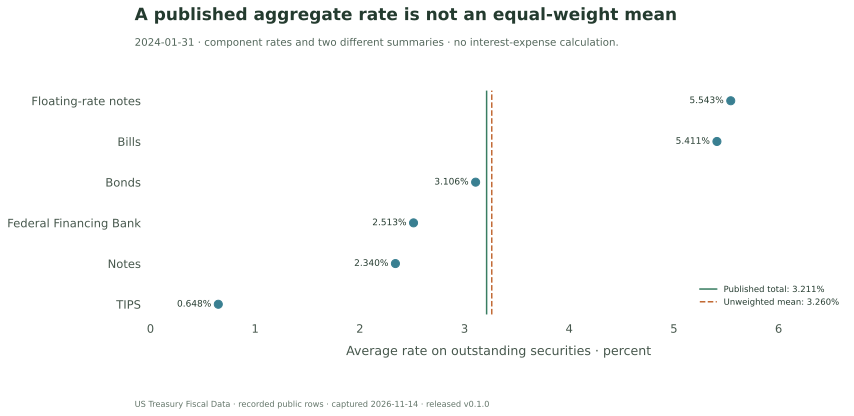

In [14]:
fig, ax = plt.subplots(figsize=(11, 6.1))
y = np.arange(len(rates))
ax.scatter(rates.rate_percent, y, s=65, color="#397F91", zorder=3)
ax.axvline(
    float(rate_summary.published_pct),
    color="#397D62",
    linewidth=1.5,
    label=f"Published total: {float(rate_summary.published_pct):.3f}%",
)
ax.axvline(
    float(rate_summary.unweighted_pct),
    color="#C26A35",
    linestyle="--",
    linewidth=1.5,
    label=f"Unweighted mean: {float(rate_summary.unweighted_pct):.3f}%",
)
ax.set_yticks(y, rates.short_label)
ax.set_xlabel("Average rate on outstanding securities · percent")
ax.set_xlim(0, max(rates.rate_percent) * 1.2)
for i, value in enumerate(rates.rate_percent):
    ax.annotate(
        f"{value:.3f}%", (value, i), xytext=(-7, 0), textcoords="offset points", va="center", ha="right", fontsize=9
    )
ax.legend(loc="lower right", fontsize=8.5)
finish(
    fig,
    "A published aggregate rate is not an equal-weight mean",
    f"{REPORT_DATE} · component rates and two different summaries · no interest-expense calculation.",
    PROVENANCE,
    name=f"rates-are-percentages-{REPORT_DATE}",
)

### Reconcile typed data, raw rows and the selected hierarchy

Generic records must match every typed row's preserved JSON. Parent links and row
codes must retain a single current-fiscal-year total. Monthly details should reconcile
to that total at cent precision. Rate checks preserve source strings and distinguish
component rows from the published total; no assertion forces unlike statistics equal.

In [15]:
%%sql checks <<
WITH raw_diff AS (
 (SELECT record_json::JSON FROM raw_monthly EXCEPT SELECT source_json::JSON FROM monthly)
 UNION ALL (SELECT source_json::JSON FROM monthly EXCEPT SELECT record_json::JSON FROM raw_monthly)
)
SELECT 'Generic and typed monthly rows match' AS invariant,count(*)=0 AS passed FROM raw_diff
UNION ALL SELECT 'Monthly source keys unique',count(*)=count(DISTINCT src_line_nbr) FROM monthly
UNION ALL SELECT 'Three amount fields are labelled currency',count(*)=3 AND bool_and(source_type='CURRENCY') FROM field_info WHERE field_name LIKE '%amt'
UNION ALL SELECT 'One current-fiscal-year total',count(*)=1 FROM fiscal_total
UNION ALL SELECT 'Current months have unique names and complete amounts',count(*)=count(DISTINCT classification_desc) AND bool_and(current_month_dfct_sur_amt IS NOT NULL) FROM fiscal_months
UNION ALL SELECT 'Deficit equals outlays minus receipts',bool_and(current_month_dfct_sur_amt=current_month_gross_outly_amt-current_month_gross_rcpt_amt) FROM fiscal_months
UNION ALL SELECT 'Monthly deficits sum to YTD',(SELECT sum(current_month_dfct_sur_amt) FROM fiscal_months)=(SELECT current_month_dfct_sur_amt FROM fiscal_total)
UNION ALL SELECT 'Monthly receipts sum to YTD',(SELECT sum(current_month_gross_rcpt_amt) FROM fiscal_months)=(SELECT current_month_gross_rcpt_amt FROM fiscal_total)
UNION ALL SELECT 'Header amounts remain missing',bool_and(current_month_gross_rcpt_amt IS NULL AND current_month_gross_outly_amt IS NULL) FROM monthly WHERE data_type_cd='S'
UNION ALL SELECT 'Six marketable components',count(*)=6 AND count(DISTINCT security_desc)=6 FROM marketable_rates
UNION ALL SELECT 'Source rates retain exact percentages',bool_and(avg_interest_rate_amt=(source_json::JSON->>'avg_interest_rate_amt')::DECIMAL(38,6) AND amount_units='percent') FROM interest
UNION ALL SELECT 'Every row has the selected report date',bool_and(record_date=DATE '{{ REPORT_DATE }}') FROM (SELECT record_date FROM monthly UNION ALL SELECT record_date FROM interest);

In [16]:
display(checks)
assert len(checks) == 12 and checks.passed.notna().all() and checks.passed.all()
requests = source.audit(
    [
        ("monthly", None, None, 1, "fields"),
        ("monthly", REPORT_DATE, REPORT_DATE, 10, "records"),
        ("monthly", REPORT_DATE, REPORT_DATE, 10, "records"),
        ("rates", REPORT_DATE, REPORT_DATE, 10, "records"),
    ]
)
prose(
    f"All **{len(checks)} SQL checks** pass, with exactly **{requests} local GETs**, including "
    "separate generic and typed monthly scans. Field metadata and original capture hashes are unchanged."
)
Path("artifacts/monthly-audit.json").write_text(
    json.dumps(
        {
            "report_date": REPORT_DATE,
            "requests": requests,
            "report_population": report_population,
            "months": months.to_dict("records"),
            "rates": rates.to_dict("records"),
            "rate_summary": rate_summary.to_dict(),
            "ytd_deficit_api_units": ytd,
            "field_info": connection.execute("SELECT * FROM field_info ORDER BY field_name")
            .fetchdf()
            .to_dict("records"),
            "checks": checks.to_dict("records"),
        },
        indent=2,
        default=str,
    )
)

,invariant,passed
0,Generic and typed monthly rows match,True
1,Monthly source keys unique,True
2,Three amount fields are labelled currency,True
3,One current-fiscal-year total,True
4,Current months have unique names and complete ...,True
5,Deficit equals outlays minus receipts,True
6,Monthly deficits sum to YTD,True
7,Monthly receipts sum to YTD,True
8,Header amounts remain missing,True
9,Six marketable components,True


All **12 SQL checks** pass, with exactly **7 local GETs**, including separate generic and typed monthly scans. Field metadata and original capture hashes are unchanged.

5960

### Experiment: move to February's report population

Use `REPORT_DATE = "2024-02-29"` in a separate copy. Expect an additional current-year
monthly detail, while retaining prior-year rows and totals outside that detail set.
Compare the YTD deficit and each rate without assuming a direction. Field metadata,
source bytes and definition checks stay fixed. This is a report-population comparison,
not a claim that every earlier amount is unrevised or a forecast of future financing.

In [17]:
assert connection.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
session.close()
source.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-treasury](https://github.com/Query-farm/vgi-treasury)